# Checkpoint 1 - Visa equity-research desk

**FIN 67110 | Company: Visa (NYSE: V) | Information cutoff: November 3, 2026**

This notebook runs Lab 2's seven filing-data steps and implements Lab 3's four
model roles. The reusable implementation is in [`desk.py`](desk.py); only this
notebook's configuration selects Visa. The saved run includes filings, facts,
ratios, a five-part **fallback report**, and a blank human-audit worksheet.

**Execution status:** the seven steps can replay completely offline. No model API
key was configured when this artifact was created, so the four live SDK calls
have not been exercised against the provider. The fallback is allowed by Week 2
and is labelled on its second line. Turn on `RUN_MODEL_ROLES` after adding a key
locally to generate a separate live report. The human audit and partner marks
are intentionally unfinished, as required by the assignment.

| Requirement | Where it is implemented |
|---|---|
| Ticker to CIK; latest annual, quarterly and earnings filings | Steps 1-2 |
| Filing index accession and Accepted time; earnings Item 2.02 | Step 2 |
| 10-K, 10-Q and Exhibit 99.1 saved as line-addressable text | Step 3 |
| Latest annual facts, candidate tags, periods and source lines | Step 4 |
| Growth, margin, ROE, debt/equity, FCF and dated-price P/E in code | Step 5 |
| Quarter revenue and GAAP diluted EPS quoted from the release | Step 6 |
| Peers from their own annual filings, with the same GAAP margin formula | Step 7 |
| Four separate role calls; JSON hand-offs; one revision loop | Live roles section and desk.py |
| Five-part report, source accessions on line one, run time on line two | Report section |
| Exact eleven-claim audit, human marks, counts and partner checks | human_audit.md beside the report |
| Anthropic human sign-off learning answers and review record | Human sign-off section and human_signoff.md |

References: [Lab 2](../Instructions/Lab%202.pdf),
[Week 2](../Instructions/Week%202.pdf), [Lab 3](../Instructions/Lab%203.pdf),
and [Francis & Zhang (2026), section 3.1 and Figures 1-2](../Documents/Projects/Mas.AI.Fin/FRL-CanAIReplaceAnalyst.pdf).

Additional supplied references: [Report Audit.pdf](../Instructions/Report%20Audit.pdf),
pages 1-3, and [Anthropic Open Source.pdf](../Instructions/Anthropic%20Open%20Source.pdf),
pages 1-2 for the human sign-off notice and Earnings Reviewer.


## Setup and configuration

From the repository root install dependencies once:

```powershell
python -m pip install -r "Checkpoint 1/requirements.txt"
```

Use a Python 3.11+ kernel and **Run All**. The default replays the recorded SEC
responses and the **actual LSEG price observation** without network requests.
The receipt records the instrument, field, unadjusted-price request, trade date,
retrieval time and data-file hash. It does not contain credentials.

Set `OFFLINE = False` for a new run. For LSEG, Workspace must be running and
signed in on this computer, with `LSEG_APP_KEY` in the repository-root `.env`.
Choose `MARKET_PROVIDER = "wrds"` to use the WRDS Compustat daily close instead;
that route reads `WRDS_USERNAME` and `WRDS_PASSWORD` from `.env` and needs database
network access and subscription permission. A failed retrieval does not fall
back to a public quote or relabel a manually entered number.

For the live model roles, separately add `API_KEY` (or `OPENAI_API_KEY`), and
optionally `OPENAI_MODEL`. `.env.example` contains placeholders only. `.env`
remains ignored by Git. Data-provider credentials do not replace a model key.


In [1]:
from pathlib import Path
import sys
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
CHECKPOINT = next((p for p in [cwd, cwd / "Checkpoint 1"] if (p / "desk.py").exists()), None)
if CHECKPOINT is None:
    raise FileNotFoundError("Open the notebook from the repository root or Checkpoint 1 folder.")
sys.path.insert(0, str(CHECKPOINT))
from desk import Desk, read_json, number, run_roles, ROLE_INSTRUCTIONS, TEMPLATE, core_audit_claims
from market_data import verify_receipt

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 12)

TICKER = "V"
PEERS = ["MA", "PYPL"]
AS_OF = "2026-11-03"
PRICE_DATE = "2026-10-27"
MARKET_PROVIDER = "lseg"
RIC = "V.N"  # Listed Class A instrument; used only by LSEG.
OFFLINE = True
RUN_MODEL_ROLES = False  # True makes live model-provider calls and incurs API usage.

recorded = CHECKPOINT / read_json(CHECKPOINT / "latest_run.json")["run_dir"]
if OFFLINE:
    saved = read_json(recorded / "configuration.json")
    assert (TICKER, PEERS, AS_OF, PRICE_DATE, MARKET_PROVIDER, RIC) == (
        saved["ticker"], saved["peers"], saved["as_of"], saved["price_date"], saved["market_provider"], saved["ric"]
    ), "Changed inputs require OFFLINE=False or a matching recorded run."

desk = Desk(TICKER, PEERS, price_date=PRICE_DATE, as_of=AS_OF,
            run_dir=recorded if OFFLINE else None, offline=OFFLINE,
            market_provider=MARKET_PROVIDER, ric=RIC)
print("Mode:", "recorded SEC and LSEG observations / offline" if OFFLINE else "new provider retrieval")
print("As of:", AS_OF, "| Run folder:", desk.run_dir.relative_to(CHECKPOINT))
print("No environment values or credentials are displayed.")


def file_markdown(text, document_path):
    """Resolve document-relative links when embedding its Markdown here."""
    import os
    from urllib.parse import urlparse, unquote
    def rewrite(match):
        target = match.group(1)
        if urlparse(target).scheme or target.startswith("#"):
            return match.group(0)
        local, separator, anchor = target.partition("#")
        relative = Path(os.path.relpath((document_path.parent / unquote(local)).resolve(), CHECKPOINT)).as_posix()
        return "](" + relative.replace(" ", "%20") + (separator + anchor if separator else "") + ")"
    return Markdown(re.sub(r"\]\(([^)]+)\)", rewrite, text))


Mode: recorded SEC and LSEG observations / offline
As of: 2026-11-03 | Run folder: runs\V_20261103T064621Z
No environment values or credentials are displayed.


## Step 1 - Resolve the ticker to its SEC CIK

Resolve the input through SEC's ticker file. The company name and CIK come from
that response, rather than a company-specific constant in the desk.

In [2]:
print("1. Resolve ticker to CIK")
company = desk.resolve(TICKER)
display(pd.DataFrame([company]))

1. Resolve ticker to CIK


,ticker,cik,name
0,V,0001403161,VISA INC.


## Step 2 - Select and identify the filings

Select the latest 10-K, latest 10-Q and latest earnings 8-K **as of the cutoff**.
An earnings 8-K must report Item 2.02; another newer 8-K cannot replace it.
For each filing the desk reads its index, prints the accession and Accepted time,
and checks that the index's Eastern time equals the API's UTC instant.

In [3]:
print("2. Select filings and verify index Accepted times")
filings = desk.select_filings(TICKER)
display(pd.DataFrame.from_dict(filings, orient="index")[[
    "form", "report_date", "filing_date", "accession", "accepted_index", "accepted_api", "items"
]])
for kind, filing in filings.items():
    display(Markdown(f"**{kind}** - [filing index]({filing['index_url']})"))

2. Select filings and verify index Accepted times


,form,report_date,filing_date,accession,accepted_index,accepted_api,items
10-K,10-K,2025-09-30,2025-11-06,0001403161-25-000089,2025-11-06 16:09:41,2025-11-06T21:09:41.000Z,
10-Q,10-Q,2026-06-30,2026-07-29,0001403161-26-000104,2026-07-28 18:08:12,2026-07-28T22:08:12.000Z,
earnings,8-K,2026-10-27,2026-10-27,0001403161-26-000126,2026-10-27 16:05:22,2026-10-27T20:05:22.000Z,"2.02,8.01,9.01"


**10-K** - [filing index](https://www.sec.gov/Archives/edgar/data/1403161/000140316125000089/0001403161-25-000089-index.html)

**10-Q** - [filing index](https://www.sec.gov/Archives/edgar/data/1403161/000140316126000104/0001403161-26-000104-index.html)

**earnings** - [filing index](https://www.sec.gov/Archives/edgar/data/1403161/000140316126000126/0001403161-26-000126-index.html)

## Step 3 - Download and save the filing text

The earnings document is the 8-K's **Exhibit 99.1**. Table rows stay together in
plain text, and citations use one-based line numbers in those saved text files.
Compressed original responses and SHA-256 hashes preserve the source evidence
needed to replay this exact run.

In [4]:
print("3. Save the 10-K, 10-Q and Exhibit 99.1")
downloaded = desk.download(TICKER)
display(pd.DataFrame.from_dict(downloaded, orient="index")[["file", "lines", "url"]])
manifest = desk.sec.manifest
print(f"Recorded public SEC responses currently available: {len(manifest)}")

3. Save the 10-K, 10-Q and Exhibit 99.1


,file,lines,url
10-K,V/10-K.txt,3848,https://www.sec.gov/Archives/edgar/data/1403161/000140316125000089/v-20250930.htm
10-Q,V/10-Q.txt,1890,https://www.sec.gov/Archives/edgar/data/1403161/000140316126000104/v-20260630.htm
earnings,V/earnings_release.txt,450,https://www.sec.gov/Archives/edgar/data/1403161/000140316126000126/q42026earningsrelea...


Recorded public SEC responses currently available: 17


## Step 4 - Extract the annual facts with provenance

The annual facts must share the latest 10-K's fiscal end and accession. Duration
facts must cover a full fiscal year, and ratios must not mix years. Candidate
revenue tags are checked against that period before selection; the prior-year
revenue uses the same tag and definition.

**Visa-specific context found in the filing:** the company-facts API omits the
dimensional Class A diluted EPS fact. The desk reads it from inline XBRL in the
10-K, selecting the Class A context explicitly. Other share classes have
different EPS. Capex is the filing's purchases of property, equipment **and
technology**. The source labels, units and contexts remain available for audit.

In [5]:
print("4. Extract annual facts, tags, periods and source lines")
facts = desk.annual_facts(TICKER)
fact_frame = pd.DataFrame.from_dict(facts, orient="index")
display(fact_frame[["value", "unit", "start", "end", "tag", "line", "method"]]
        .style.format({"value": lambda x: number(x, 2)}))
print("Class A EPS context:", facts["diluted_eps"]["context"], facts["diluted_eps"]["dimensions"])
print("EPS source:", facts["diluted_eps"]["source_text"])
print("Capex source:", facts["capex"]["source_text"])

selection = read_json(desk.run_dir / TICKER / "tag_selection.json")
display(pd.DataFrame(selection).query("metric == 'revenue'").drop_duplicates())

4. Extract annual facts, tags, periods and source lines


,value,unit,start,end,tag,line,method
revenue,"40,000,000,000.00",USD,2024-10-01,2025-09-30,us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax,1556,SEC company-facts
operating_income,"23,994,000,000.00",USD,2024-10-01,2025-09-30,us-gaap:OperatingIncomeLoss,1567,SEC company-facts
net_income,"20,058,000,000.00",USD,2024-10-01,2025-09-30,us-gaap:NetIncomeLoss,2877,SEC company-facts
diluted_eps,10.20,USD/shares,2024-10-01,2025-09-30,us-gaap:EarningsPerShareDiluted,1590,10-K inline XBRL (dimensional fallback)
equity,"37,909,000,000.00",USD,None,2025-09-30,us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest,1539,SEC company-facts
long_term_debt,"19,602,000,000.00",USD,None,2025-09-30,us-gaap:LongTermDebtNoncurrent,1516,SEC company-facts
current_debt,"5,569,000,000.00",USD,None,2025-09-30,us-gaap:LongTermDebtCurrent,1513,SEC company-facts
operating_cash_flow,"23,059,000,000.00",USD,2024-10-01,2025-09-30,us-gaap:NetCashProvidedByUsedInOperatingActivities,1775,SEC company-facts
capex,"1,482,000,000.00",USD,2024-10-01,2025-09-30,us-gaap:PaymentsToAcquireProductiveAssets,1777,SEC company-facts
prior_revenue,"35,926,000,000.00",USD,2023-10-01,2024-09-30,us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax,1556,SEC company-facts


Class A EPS context: c-2 {'us-gaap:StatementClassOfStockAxis': 'us-gaap:CommonClassAMember'}
EPS source: Class A common stock | $ | 10.20 | | | $ | 9.73 | | | $ | 8.28 |
Capex source: Purchases of property, equipment and technology | ( 1,482 ) | | | ( 1,257 ) | | | ( 1,059 ) |


,metric,candidate,target_end,latest_available_end
0,revenue,us-gaap:Revenues,2025-09-30,2020-09-30
1,revenue,us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax,2025-09-30,2026-03-31
2,revenue,us-gaap:RevenueFromContractWithCustomerIncludingAssessedTax,2025-09-30,None
3,revenue,us-gaap:SalesRevenueNet,2025-09-30,None
17,revenue,us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax,2024-09-30,2026-03-31


## Step 5 - Compute ratios using a retrieved provider close

The Financial Analyst receives Python-calculated results. Revenue growth uses
the same definition in both annual periods. ROE uses average beginning/ending
equity, debt includes the current portion, and FCF deducts the stated capital
outflow from operating cash flow.

The price is retrieved through **LSEG Historical Pricing**, instrument `V.N`,
field `TRDPRC_1`, daily frequency, with the `unadjusted` setting. The recorded
observation is the October 27, 2026 close, before the earnings 8-K's acceptance.
Offline replay verifies its receipt and CSV hash rather than querying again.

P/E uses **the latest filed annual Class A GAAP EPS**, so it remains an annual-
filing multiple based on fiscal 2025, not a current TTM multiple. Newer earnings
release EPS is shown separately. Percent ratios are stored as percentage points.


In [6]:
print("5. Retrieve/verify the provider close and calculate ratios in Python")
ratios = desk.calculate(TICKER, include_price=True)
PRICE = desk.price
PRICE_SOURCE = desk.price_source
price_receipt = verify_receipt(desk.run_dir, TICKER, PRICE_DATE, MARKET_PROVIDER)
display(pd.DataFrame.from_dict(ratios, orient="index")[["value", "unit", "arithmetic", "fiscal_end"]]
        .style.format({"value": lambda x: number(x, 2)}))
display(pd.DataFrame([{key: price_receipt[key] for key in [
    "provider", "instrument", "field", "trade_date", "close_usd", "retrieved_at_utc"
]}]))
print("Price provenance:", PRICE_SOURCE)
print("Verified observation SHA-256:", price_receipt["sha256"])
receipt_link = (desk.run_dir / "market_input.json").relative_to(CHECKPOINT).as_posix()
data_link = (desk.run_dir / price_receipt["data_file"]).relative_to(CHECKPOINT).as_posix()
display(Markdown(f"[Retrieval receipt]({receipt_link}) | [Recorded market observation]({data_link})"))


5. Retrieve/verify the provider close and calculate ratios in Python


,value,unit,arithmetic,fiscal_end
revenue_growth,11.34,%,"(40,000,000,000 / 35,926,000,000 - 1) * 100",2025-09-30
operating_margin,59.99,%,"23,994,000,000 / 40,000,000,000 * 100",2025-09-30
return_on_average_equity,52.07,%,"20,058,000,000 / ((39,137,000,000 + 37,909,000,000) / 2) * 100",2025-09-30
debt_to_equity,0.66,x,"(19,602,000,000 + 5,569,000,000) / 37,909,000,000",2025-09-30
free_cash_flow,"21,577,000,000.00",USD,"23,059,000,000 - 1,482,000,000",2025-09-30
price_earnings,39.40,x,401.86 / 10.20,2025-09-30


,provider,instrument,field,trade_date,close_usd,retrieved_at_utc
0,LSEG,V.N,TRDPRC_1,2026-10-27,401.86,2026-11-03T07:29:18.573577+00:00


Price provenance: LSEG Historical Pricing; V.N; TRDPRC_1; daily close; 2026-10-27; unadjusted
Verified observation SHA-256: 50e2eecfbf44c0b5cb8c5b8659f68a6951f97321ff6b1c5eb3be50b3d7b5d5a7


[Retrieval receipt](runs/V_20261103T064621Z/market_input.json) | [Recorded market observation](runs/V_20261103T064621Z/market_data/lseg_close.csv)

## Step 6 - Read the latest quarter from the release

The release contains both quarterly and full-year columns. Read the headers
before using the values. The 8-K event date is the announcement date, not the
quarter end. The code reads the GAAP statement's current and prior-year quarter
columns, selects Class A diluted EPS, and calculates the quarter's nominal
revenue growth in Python. This supplies audit claims 9-11 directly.

The exact headers and rows are printed below. Full-year EPS remains separately
labelled; a rounded headline or adjusted EPS cannot replace a core GAAP claim.


In [7]:
print("6. Read quarterly revenue and GAAP EPS source lines")
quarter_sources = desk.release_quarter()
print("Release:", quarter_sources["release_date"], "| Quarter ended:", quarter_sources["period_end"])
for item in [quarter_sources["revenue_candidates"][0], quarter_sources["eps_candidates"][0]]:
    print(f"{quarter_sources['file']} L{item['line']}: {item['text']}")

observations_path = desk.run_dir / "quarter_observations.json"
if observations_path.exists():
    observations = read_json(observations_path)
    assert observations["accession"] == quarter_sources["accession"]
    release_lines = desk.documents[TICKER]["earnings"]["lines"]
    cited_lines = observations["column_headers_lines"] + sorted({
        v["line"] for v in observations["observations"].values()
    })
    print("\nExact statement headers and source rows:")
    for line in cited_lines:
        print(f"L{line}: {release_lines[line - 1]}")
    for name, observation in observations["observations"].items():
        row = release_lines[observation["line"] - 1]
        values = [float(s.strip().replace(",", "").replace("$", "")) for s in row.split("|")
                  if re.fullmatch(r"\s*\$?\s*[\d,]+(?:\.\d+)?\s*", s)]
        source_value = observation["value"] / 1_000_000 if observation["unit"] == "USD" else observation["value"]
        assert source_value in values, f"Observation no longer appears in its cited row: {name}"
    display(pd.DataFrame.from_dict(observations["observations"], orient="index"))
    qgrowth = observations["calculated_quarter_revenue_growth"]
    print("Quarterly nominal revenue growth:", qgrowth["arithmetic"], "=", number(qgrowth["value"]), "%")
else:
    print("New run: inspect the full candidate source lines and record the quarter's exact columns before reporting numbers.")

6. Read quarterly revenue and GAAP EPS source lines
Release: 2026-10-27 | Quarter ended: 2026-09-30
V/earnings_release.txt L10: • Net revenue of $12.1B, an increase of 13% on a nominal and constant-dollar basis
V/earnings_release.txt L9: • GAAP net income of $6.0B or $3.19 per share and non-GAAP net income of $6.6B or $3.48 per share

Exact statement headers and source rows:
L203: | Three Months Ended September 30, | | Twelve Months Ended September 30,
L204: | 2026 | | 2025 | | 2026 | | 2025
L205: | (in millions, except per share data)
L212: Net revenue | $ | 12,139 | | | $ | 10,724 | | | $ | 45,903 | | | $ | 40,000 |
L250: Class A common stock | $ | 3.19 | | | $ | 2.62 | | | $ | 12.32 | | | $ | 10.20 |


,value,unit,line,column
quarter_net_revenue,1.213900e+10,USD,212,First quarter column; three months ended 2026-09-30; source in millions
prior_quarter_net_revenue,1.072400e+10,USD,212,Second quarter column; same quarter of prior year; source in millions
quarter_gaap_diluted_eps,3.190000e+00,USD/shares,250,"First quarter column, GAAP diluted EPS; us-gaap:CommonClassAMember"
annual_release_gaap_diluted_eps,1.232000e+01,USD/shares,250,Third numeric column; twelve months ended 2026-09-30; us-gaap:CommonClassAMember


Quarterly nominal revenue growth: (12,139,000,000 / 10,724,000,000 - 1) * 100 = 13.19 %


## Step 7 - Compare peers using their own annual filings

The two peers are Mastercard (MA) and PayPal (PYPL). Each is resolved and read
independently. The arithmetic is identical: **GAAP operating income / reported
consolidated revenue**. Show the fiscal end and each filing's actual revenue
label. Different calendars and business models limit comparability.

The parser flags PayPal's dimensional current-debt disclosure for manual review;
it does not fill a missing aggregate with zero or calculate its debt/equity.
This does not prevent the directly supported revenue and margin comparison.

In [8]:
print("7. Read peer annual filings and calculate comparable margins")
peer_results = desk.compare_peers()
peer_rows = []
for ticker in [TICKER] + PEERS:
    pf = desk.facts[ticker]
    margin = desk.ratios[ticker]["operating_margin"]
    peer_rows.append({"ticker": ticker, "fiscal_end": pf["revenue"]["end"],
        "revenue_USD_bn": pf["revenue"]["value"] / 1e9,
        "operating_income_USD_bn": pf["operating_income"]["value"] / 1e9,
        "GAAP_operating_margin_pct": margin["value"],
        "revenue_label": pf["revenue"]["source_text"].split("|")[0].strip(),
        "accession": pf["revenue"]["accession"]})
peer_frame = pd.DataFrame(peer_rows).set_index("ticker")
display(peer_frame.style.format({"revenue_USD_bn": "{:.3f}", "operating_income_USD_bn": "{:.3f}",
    "GAAP_operating_margin_pct": lambda x: number(x)}))
for ticker in PEERS:
    unavailable = read_json(desk.run_dir / ticker / "unavailable_facts.json")
    if unavailable:
        print(ticker, "fields needing review:", unavailable)
desk.save()

7. Read peer annual filings and calculate comparable margins


,fiscal_end,revenue_USD_bn,operating_income_USD_bn,GAAP_operating_margin_pct,revenue_label,accession
ticker,,,,,,
V,2025-09-30,40.000,23.994,59.99,Net revenue,0001403161-25-000089
MA,2025-12-31,32.791,18.897,57.63,Net Revenue,0001141391-26-000013
PYPL,2025-12-31,33.172,6.065,18.28,Net revenues,0001633917-26-000024


PYPL fields needing review: {'current_debt': 'Missing or ambiguous current_debt for PYPL, 2025-12-31. No stale/zero substitution.'}


WindowsPath('C:/Users/josep/orca/Financial-Analysis/Checkpoint 1/runs/V_20261103T064621Z')

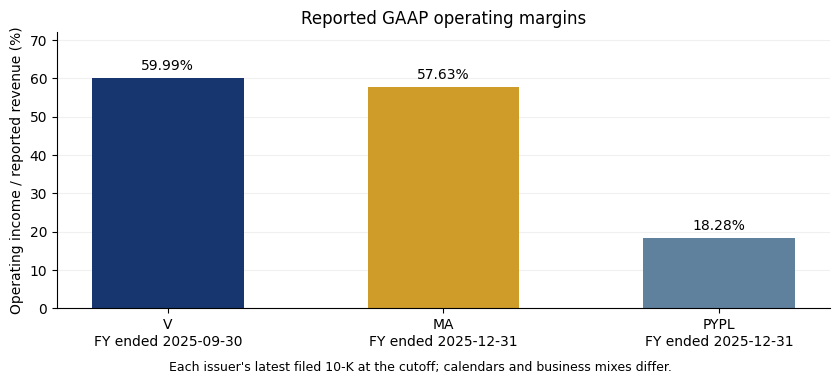

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels = [f"{ticker}\nFY ended {row.fiscal_end}" for ticker, row in peer_frame.iterrows()]
bars = ax.bar(labels, peer_frame["GAAP_operating_margin_pct"], color=["#17366F", "#CF9C2A", "#5F819D"], width=0.55)
ax.bar_label(bars, labels=[f"{number(v)}%" for v in peer_frame["GAAP_operating_margin_pct"]], padding=4)
ax.set(title="Reported GAAP operating margins", ylabel="Operating income / reported revenue (%)", ylim=(0, 72))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
fig.text(0.5, 0.01, "Each issuer's latest filed 10-K at the cutoff; calendars and business mixes differ.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 1))
chart_path = desk.run_dir / "peer_operating_margins.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()

## The four roles and the Strategy Manager's hand-offs

1. **Research Analyst:** filing-based business model, competition, catalysts and developments, with short source quotations.
2. **Financial Analyst:** the canonical facts, Python ratios, quarter and peers; explicit definitions and source tokens.
3. **Investment Advisor:** only the two analysts' outputs; Buy/Hold/Sell and one deciding metric.
4. **Strategy Manager:** model review plus code checks; send a failing part back once, then compile only if review passes.

Each role is a separate call using the official OpenAI Python SDK. The Manager's
JSON hand-off contains `task`, `context`, and `expected_output`; the advisor does
not retrieve new evidence. Numeric tokens are expanded by code with provenance.
Inputs, outputs and model metadata are saved under `model_roles/` for live runs.
The manager checks completeness and consistency; the human still audits truth.

The SDK follows the [official Python documentation](https://developers.openai.com/api/reference/python)
and [structured-output schema](https://developers.openai.com/api/docs/guides/structured-outputs?api-mode=responses).
No API call is made unless `RUN_MODEL_ROLES = True`. Missing keys, refusals or
failed review raise an error instead of silently presenting a completed run.

The Financial Analyst and Strategy Manager also receive the exact eleven claim
categories from the supplied [Report Audit.pdf](../Instructions/Report%20Audit.pdf).
The deterministic financial tables include quarter revenue, quarter growth from
the two quarter columns, and GAAP diluted EPS. Model review does not supply any
of the human's audit marks or sign-off fields.


In [10]:
for role, instructions in ROLE_INSTRUCTIONS.items():
    display(Markdown(f"**{role}**\n\n{instructions}"))

if RUN_MODEL_ROLES:
    report_path = run_roles(desk)
    REPORT_MODE = "live provider calls"
else:
    report_path = desk.run_dir / "fallback_report.md"
    REPORT_MODE = "course-permitted fallback; live roles were not run"
    if not report_path.exists():
        raise FileNotFoundError("This new run has no fallback. Enable RUN_MODEL_ROLES after configuring a model API key.")
print("Report mode:", REPORT_MODE)
print("Saved report:", report_path.relative_to(CHECKPOINT))

**Research Analyst**

Analyze the business model, competitive position, catalysts, recent developments, and risks. Use only the filing excerpts supplied by the Strategy Manager. Each factual claim must carry an exact short quote and a [K:Lx], [Q:Lx] or [E:Lx] citation from that packet. Keep total verbatim quotations under twenty-five words per filing. Distinguish your inference from a filing fact. Return only your three assigned sections.

**Financial Analyst**

Interpret the supplied annual facts, Python-calculated ratios, quarterly source lines, and peer table. Never calculate or invent a number. All numeric claims must use a supplied {{fact:KEY}}, {{ratio:KEY}}, {{quarter:KEY}} or {{release:KEY}} token, which code expands with its source or arithmetic. Cover the instructor's eleven core claims. Discuss GAAP versus non-GAAP, the annual/quarterly period difference, the revenue definition, debt current portion, average equity, capex scope, and peer comparability. The deterministic tables are appended by the harness. Return only Valuation Insights.

**Investment Advisor**

Synthesize only the Research Analyst and Financial Analyst outputs provided by the Manager. Return an explicit Buy, Hold or Sell recommendation and a thesis; choose exactly one deciding ratio from available decision metrics and use its {{ratio:KEY}} token in the text. State the investment judgment and key risks without inventing a target price or forecast. Return only Investment Recommendation.

**Strategy Manager**

Review the supplied drafts for all five required sections, the instructor's eleven core claims, consistency with the supplied evidence and canonical numbers, explicit GAAP definitions, annual versus quarterly periods, comparable peer margins, and a Buy/Hold/Sell with exactly one deciding metric. Return approved true only if these pass. For each failing part name its owner and a specific repair. A draft may be sent back once. Your approval is a structural draft review only; you cannot fill human audit marks or provide human sign-off.

Report mode: course-permitted fallback; live roles were not run
Saved report: runs\V_20261103T064621Z\fallback_report.md


## Five-part report

The first line identifies all filings read and their accessions; the second line
records run time and identifies the fallback. The saved Markdown is the report
artifact to review alongside this notebook.

In [11]:
report_text = report_path.read_text(encoding="utf-8")
assert [line[3:] for line in report_text.splitlines() if line.startswith("## ")] == TEMPLATE
print("Metadata line 1:", report_text.splitlines()[0])
print("Metadata line 2:", report_text.splitlines()[1])
display(file_markdown(report_text, report_path))

Metadata line 1: VISA INC. (NYSE: V); filings read: V 10-K 0001403161-25-000089; V 10-Q 0001403161-26-000104; V earnings 0001403161-26-000126; MA 10-K 0001141391-26-000013; PYPL 10-K 0001633917-26-000024
Metadata line 2: fallback; run time (UTC): 2026-11-03T07:35:07.016502+00:00; assistant synthesis using the saved filings; price retrieved directly from LSEG; four live model-provider calls were not run because no model API key was configured.


VISA INC. (NYSE: V); filings read: V 10-K 0001403161-25-000089; V 10-Q 0001403161-26-000104; V earnings 0001403161-26-000126; MA 10-K 0001141391-26-000013; PYPL 10-K 0001633917-26-000024
fallback; run time (UTC): 2026-11-03T07:35:07.016502+00:00; assistant synthesis using the saved filings; price retrieved directly from LSEG; four live model-provider calls were not run because no model API key was configured.

## Overview

**Research Analyst.** Visa connects participants in electronic payments through its transaction network. Its filing describes a "single connection point" and states "We do not issue cards"; this distinguishes the network's operating model from a card issuer's lending business. [K1, K2] The annual data below cover the fiscal year ended September 30, 2025. The quarterly update covers the three months ended September 30, 2026 and comes from the October earnings release. [K3, E1]

## Market Positioning and Growth Outlook

**Research Analyst.** The annual filing names "Mastercard" among the competing payment networks. [K4] The latest quarterly filing attributes volume support to "consumer spending" and "digital commerce" while identifying incentives as an offset to growth. [Q1] The annual MD&A also identifies "higher client incentives" as an offset to revenue growth. [K5] My inference is that transaction demand and incentive discipline should be assessed together; growth in payment activity alone does not establish stronger economics.

For the latest fiscal quarter, net revenue was **$12.139 billion**, and Class A GAAP diluted EPS was **$3.19**. The corresponding prior-year quarter revenue was **$10.724 billion**; nominal revenue growth calculated in Python is **13.19%**: `(12,139,000,000 / 10,724,000,000 - 1) * 100`. The release rounds this to 13%. [E1, E2] These are quarterly figures, rather than year-to-date or full-year results. The release also supplies non-GAAP EPS; the report uses the GAAP Class A measure. [E2, E3]

## Valuation Insights

**Financial Analyst.** The annual analysis uses the latest available 10-K, for fiscal 2025, even though a newer full-year earnings release is available. Revenue is the consolidated **net revenue after client incentives** shown in that filing. Operating margin is GAAP operating income divided by this net revenue; it includes reported litigation costs. [K3] It is not a gross margin on gross payment volume.

Debt-to-equity includes both the current and noncurrent carrying amounts of long-term debt. ROE uses beginning and ending reported stockholders' equity. Free cash flow deducts the filing's purchases of property, equipment and technology from operating cash flow; it is this desk's stated definition, not a substituted management-adjusted measure. Source tags and source lines are printed beside every input below.

The price input is LSEG's unadjusted daily close, **$401.86 on October 27, 2026**, immediately before the earnings 8-K's **16:05:22 Eastern** acceptance. [P1, F1] The required annual-filing P/E is **39.40x**, calculated as `401.86 / 10.20` using fiscal 2025 GAAP diluted EPS. **This is an annual-filing P/E with an older denominator; it is not a current trailing-twelve-month multiple.** The release separately reports newer annual Class A GAAP diluted EPS of **$12.32**, in a different column from the quarter. [E2] Do not mix the two bases or annualize a single quarter.

### Financial Analyst: annual statement facts

USD unless stated otherwise. Each row is from the selected annual filing.

| Metric | Value | Source, tag and period |
|---|---:|---|
| revenue (USD) | 40,000,000,000 | V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| operating_income (USD) | 23,994,000,000 | V/10-K.txt L1567; us-gaap:OperatingIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| net_income (USD) | 20,058,000,000 | V/10-K.txt L2877; us-gaap:NetIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| diluted_eps (USD/shares) | 10.20 | V/10-K.txt L1590; us-gaap:EarningsPerShareDiluted; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| equity (USD) | 37,909,000,000 | V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; instant to 2025-09-30; 0001403161-25-000089 |
| long_term_debt (USD) | 19,602,000,000 | V/10-K.txt L1516; us-gaap:LongTermDebtNoncurrent; instant to 2025-09-30; 0001403161-25-000089 |
| current_debt (USD) | 5,569,000,000 | V/10-K.txt L1513; us-gaap:LongTermDebtCurrent; instant to 2025-09-30; 0001403161-25-000089 |
| operating_cash_flow (USD) | 23,059,000,000 | V/10-K.txt L1775; us-gaap:NetCashProvidedByUsedInOperatingActivities; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| capex (USD) | 1,482,000,000 | V/10-K.txt L1777; us-gaap:PaymentsToAcquireProductiveAssets; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| prior_revenue (USD) | 35,926,000,000 | V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2023-10-01 to 2024-09-30; 0001403161-25-000089 |
| prior_equity (USD) | 39,137,000,000 | V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; instant to 2024-09-30; 0001403161-25-000089 |

### Calculated ratios

| Metric | Value | Arithmetic and source inputs |
|---|---:|---|
| revenue_growth | 11.34 % | (40,000,000,000 / 35,926,000,000 - 1) * 100 = 11.34; V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2024-10-01 to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2023-10-01 to 2024-09-30; 0001403161-25-000089 |
| operating_margin | 59.99 % | 23,994,000,000 / 40,000,000,000 * 100 = 59.99; V/10-K.txt L1567; us-gaap:OperatingIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| return_on_average_equity | 52.07 % | 20,058,000,000 / ((39,137,000,000 + 37,909,000,000) / 2) * 100 = 52.07; V/10-K.txt L2877; us-gaap:NetIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; instant to 2024-09-30; 0001403161-25-000089; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; instant to 2025-09-30; 0001403161-25-000089 |
| debt_to_equity | 0.66 x | (19,602,000,000 + 5,569,000,000) / 37,909,000,000 = 0.66; V/10-K.txt L1516; us-gaap:LongTermDebtNoncurrent; instant to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1513; us-gaap:LongTermDebtCurrent; instant to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; instant to 2025-09-30; 0001403161-25-000089 |
| free_cash_flow | 21,577,000,000.00 USD | 23,059,000,000 - 1,482,000,000 = 21,577,000,000.00; V/10-K.txt L1775; us-gaap:NetCashProvidedByUsedInOperatingActivities; 2024-10-01 to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1777; us-gaap:PaymentsToAcquireProductiveAssets; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| price_earnings | 39.40 x | 401.86 / 10.20 = 39.40; V/10-K.txt L1590; us-gaap:EarningsPerShareDiluted; 2024-10-01 to 2025-09-30; 0001403161-25-000089; supplied close 2026-10-27, LSEG Historical Pricing; V.N; TRDPRC_1; daily close; 2026-10-27; unadjusted |

### Peer operating margins

GAAP operating income / reported consolidated revenue. Fiscal calendars and business mixes differ.

| Ticker | Fiscal end | Revenue (USD) | Operating income (USD) | Margin | Sources |
|---|---|---:|---:|---:|---|
| V | 2025-09-30 | 40,000,000,000 | 23,994,000,000 | 59.99% | 23,994,000,000 / 40,000,000,000 * 100; V/10-K.txt L1556; us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax; 2024-10-01 to 2025-09-30; 0001403161-25-000089; V/10-K.txt L1567; us-gaap:OperatingIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089 |
| MA | 2025-12-31 | 32,791,000,000 | 18,897,000,000 | 57.63% | 18,897,000,000 / 32,791,000,000 * 100; MA/10-K.txt L1779; us-gaap:Revenues; 2025-01-01 to 2025-12-31; 0001141391-26-000013; MA/10-K.txt L1786; us-gaap:OperatingIncomeLoss; 2025-01-01 to 2025-12-31; 0001141391-26-000013 |
| PYPL | 2025-12-31 | 33,172,000,000 | 6,065,000,000 | 18.28% | 6,065,000,000 / 33,172,000,000 * 100; PYPL/10-K.txt L1212; us-gaap:Revenues; 2025-01-01 to 2025-12-31; 0001633917-26-000024; PYPL/10-K.txt L1222; us-gaap:OperatingIncomeLoss; 2025-01-01 to 2025-12-31; 0001633917-26-000024 |

### Latest earnings-release quarter

| Claim | Value | Source and period |
|---|---:|---|
| quarter_net_revenue | 12,139,000,000.00 USD | V/earnings_release.txt L212; First quarter column; three months ended 2026-09-30; source in millions; 0001403161-26-000126 |
| quarter_gaap_diluted_eps | 3.19 USD/shares | V/earnings_release.txt L250; First quarter column, GAAP diluted EPS; us-gaap:CommonClassAMember; 0001403161-26-000126 |
| Quarter revenue growth versus same quarter last year | 13.19% | (12,139,000,000 / 10,724,000,000 - 1) * 100; V/earnings_release.txt L212; quarter ended 2026-09-30; 0001403161-26-000126 |

The peer calculation uses each issuer's latest annual filing as of the run date. The same GAAP formula is applied to reported consolidated revenue, but different fiscal calendars, revenue recognition and product mixes limit direct economic comparability. Mastercard is a network comparator; PayPal's wallet and processing model differs. Peer ratios do not establish a peer valuation multiple. PayPal's current-debt fact is dimensional; the unreviewed aggregate is left unavailable, and no PayPal debt-to-equity ratio is calculated. See `PYPL/unavailable_facts.json` and the debt note at `PYPL/10-K.txt` L2942-L2947.

## Future Developments and Strategic Recommendations

**Research Analyst.** Visa identifies "value-added services" as a strategic growth area. [K6] The release describes the proposed BioCatch acquisition as "subject to customary closing conditions"; completion remains conditional. [E4] The quarterly filing also discusses the UK interchange litigation and the finding that certain "interchange rates restrict competition". [Q2] These are reported developments, not a prediction of their outcome.

My inference is to monitor service adoption, incentive discipline, acquisition execution and legal costs before extrapolating historical margins. I would first revise the Financial Analyst's instructions if a draft mixed share classes or annual periods: the correct source tag can still produce a misleading valuation when its context is wrong.

## Investment Recommendation

**Investment Advisor. Hold.** The thesis combines a profitable payment-network model with continued demand for digital commerce, while incentive competition, legal matters and acquisition execution remain material considerations. The deciding number in this educational recommendation is the **39.40x annual-filing P/E** (`$401.86 / $10.20`; [P1] and fiscal 2025 Class A diluted EPS at `V/10-K.txt` L1590, tag `us-gaap:EarningsPerShareDiluted`, Class A context, accession `0001403161-25-000089`). I would retain Hold pending a valuation built on the newer earnings base and a completed human audit. The observed multiple alone does not establish fair value, and this report supplies no unsupported target price or earnings forecast. This judgment uses only the Research Analyst and Financial Analyst material above.

**Strategy Manager.** All five requested sections are present. Quantitative tables and formulas were generated in Python from saved filing evidence. This fallback is not represented as four completed provider API calls. Human marks and partner checks remain pending in `human_audit.md`.

### Source register

- K1: `V/10-K.txt` L153; proprietary transaction network and connection model.
- K2: `V/10-K.txt` L209; card issuance and credit risk distinction.
- K3: `V/10-K.txt` L1556-L1590; annual operating statement and Class A diluted EPS; individual balance-sheet and cash-flow references are in the tables.
- K4: `V/10-K.txt` L385; named payment-network competitors.
- K5: `V/10-K.txt` L839; annual MD&A revenue drivers and incentive offset.
- K6: `V/10-K.txt` L214; growth strategy.
- Annual filing, accession `0001403161-25-000089`: https://www.sec.gov/Archives/edgar/data/1403161/000140316125000089/v-20250930.htm
- Q1: `V/10-Q.txt` L1402; quarterly MD&A transaction-volume discussion.
- Q2: `V/10-Q.txt` L1180; UK interchange litigation.
- Quarterly filing, accession `0001403161-26-000104`: https://www.sec.gov/Archives/edgar/data/1403161/000140316126000104/v-20260630.htm
- E1: `V/earnings_release.txt` L203-L205 and L212; period headers, units and consolidated net revenue.
- E2: `V/earnings_release.txt` L249-L250; diluted EPS heading and Class A row, quarter and full-year columns.
- E3: `V/earnings_release.txt` L24-L26; separately labelled GAAP and non-GAAP EPS.
- E4: `V/earnings_release.txt` L68; conditional BioCatch transaction.
- Earnings release, accession `0001403161-26-000126`, Exhibit 99.1: https://www.sec.gov/Archives/edgar/data/1403161/000140316126000126/q42026earningsrelease.htm
- F1: 8-K index, accession `0001403161-26-000126`: https://www.sec.gov/Archives/edgar/data/1403161/000140316126000126/0001403161-26-000126-index.html
- P1: `market_input.json` and `market_data/lseg_close.csv`; LSEG Historical Pricing, instrument `V.N`, field `TRDPRC_1`, adjustments `unadjusted`, trade date `2026-10-27`. Retrieved `2026-11-03T07:29:18.573577+00:00`; the receipt records the exact request and SHA-256 hash of the saved observation. Documentation: https://developers.lseg.com/en/api-catalog/lseg-data-platform/lseg-data-library-for-python/tutorials/access-tutorials/tutorial-4-get_history

Human audit status: **not completed**. Automated extraction and calculations do not constitute the lab's human sign-off.

### Human sign-off

The [human sign-off learning section](runs/V_20261103T064621Z/human_signoff.md) answers Lab 3's three
questions from the provided Anthropic Open Source.pdf (pages 1-2) and original
README. The [human audit worksheet](runs/V_20261103T064621Z/human_audit.md) now follows Report Audit.pdf's
exact eleven core claims, then the other Financial Analyst numbers, template
and recommendation checks. The review record includes error/missing counts,
two partner checks, the reviewed version, reviewer/date and a decision.

This report remains an educational draft pending human verification. The
learning explanation is complete; human findings and approval are not claimed.


## Reproducibility checks and the instructor's audit

The checks below verify extraction invariants, arithmetic and the LSEG receipt.
The supplied [Report Audit.pdf](../Instructions/Report%20Audit.pdf), pages 1-3,
defines the exact eleven core claims, the other Financial Analyst numbers, and
the template/recommendation rows. The worksheet now follows that definition and
order, including **not in filings** as its fifth mark category. Errors count
wrong plus unsupported; missing is counted separately.

The automated checks do not fill the human's Filing says or Mark columns. A
human must open the filings, verify definitions, record the two partner checks,
and decide whether to approve the reviewed draft or return it for revision.


In [12]:
from math import isclose
annual = desk.filings[TICKER]["10-K"]
assert all(v["end"] == annual["report_date"] for k, v in facts.items() if not k.startswith("prior_"))
assert all(v["accession"] == annual["accession"] for v in facts.values())
assert all(v["start"] == facts["revenue"]["start"] for k, v in facts.items()
           if v["start"] and not k.startswith("prior_"))
assert facts["revenue"]["tag"] == facts["prior_revenue"]["tag"]
for ticker, tfacts in desk.facts.items():
    for name, value in tfacts.items():
        saved_lines = (desk.run_dir / value["file"]).read_text(encoding="utf-8").splitlines()
        assert saved_lines[value["line"] - 1] == value["source_text"], (ticker, name)
    expected = tfacts["operating_income"]["value"] / tfacts["revenue"]["value"] * 100
    assert isclose(desk.ratios[ticker]["operating_margin"]["value"], expected)
assert isclose(ratios["price_earnings"]["value"], PRICE / facts["diluted_eps"]["value"])
assert ratios["free_cash_flow"]["value"] == facts["operating_cash_flow"]["value"] - facts["capex"]["value"]
assert "2.02" in desk.filings[TICKER]["earnings"]["items"]
assert quarter_sources["period_end"] != quarter_sources["release_date"]
print("PASS: fiscal periods, accession identity, source lines, peer margin formulas, P/E, FCF and earnings selection.")
print("Human audit status: PENDING - no human marks or partner checks have been supplied.")
audit_path = desk.run_dir / "human_audit.md"
display(Markdown(f"[Open the human audit worksheet]({audit_path.relative_to(CHECKPOINT).as_posix()})"))
verified_market = verify_receipt(desk.run_dir, TICKER, PRICE_DATE, MARKET_PROVIDER)
assert verified_market["provider"] in {"LSEG", "WRDS"}
assert verified_market["close_usd"] == PRICE
assert [claim["id"] for claim in core_audit_claims(desk)] == list(range(1, 12))
assert isclose(quarter_sources["revenue_growth"]["value"],
    (quarter_sources["observations"]["quarter_net_revenue"]["value"] /
     quarter_sources["observations"]["prior_quarter_net_revenue"]["value"] - 1) * 100)
print("PASS: provider receipt and data hash, exact eleven-claim mapping, and quarter-growth arithmetic.")


PASS: fiscal periods, accession identity, source lines, peer margin formulas, P/E, FCF and earnings selection.
Human audit status: PENDING - no human marks or partner checks have been supplied.


[Open the human audit worksheet](runs/V_20261103T064621Z/human_audit.md)

PASS: provider receipt and data hash, exact eleven-claim mapping, and quarter-growth arithmetic.


## The human sign-off - Learn on your own

### 1. What is it?

Anthropic's open-source financial-services repository supplies reference agents,
skills and data connectors for financial research and operations. Its Earnings
Reviewer combines earnings calls and filings into a model update and a draft
note. The README's Important notice says **"every output is staged for human
sign-off"**. The work is prepared for a qualified professional to review; the
reader remains responsible for verifying it.

Sources: [provided Anthropic Open Source.pdf, pages 1-2](../Instructions/Anthropic%20Open%20Source.pdf);
[Anthropic README, Important notice and Agents table](https://github.com/anthropics/financial-services#claude-for-financial-services).

### 2. How does it work there, and what do the agents refuse to do on their own?

The agents produce drafts and supporting analysis for review. The README
reserves investment recommendations and consequential actions for people: the
agents do not trade, commit risk, post ledger entries or approve onboarding.
An output must pass human verification before someone treats it as approved
work. Producing a well-formatted note is not approval to act on it.

Source: the same provided PDF, pages 1-2, and the README's Important notice.

### 3. What did that repository's agent have that this desk lacked?

Its README makes the human's authority and the boundary on consequential action
explicit. Our initial notebook contained source checks and a pending-audit
label, but it lacked this source-backed explanation and the instructor's exact
eleven-claim audit mapping. The update adds the explanation and review record.
The course Investment Advisor's Buy/Hold/Sell remains an **educational draft**
until a human checks and accepts or revises it. The Strategy Manager checks
report completeness; it cannot certify factual truth or sign for the student.

For this VISA INC. report, the reviewer must check the annual period, Class A GAAP
EPS, quarter-versus-full-year columns, average-equity ROE, current debt, capex
scope, peer definitions, and the retrieved market price's date and provenance.
These are evidence checks the model's fluency cannot replace.